# 🗑️ Automatic Litter Detection & Instance Segmentation using EfficientSAM
**ทีม อุดมไปด้วยธาตุเหล็ก · CP461 Computer Vision · Progress experiments**

**Pipeline:** TACO photos → **YOLO detector (trained in this notebook, 5 classes)** → bounding boxes used as prompts → **EfficientSAM-Ti / EfficientSAM-S (pretrained, zero-shot)** → instance masks + class + count

| | |
|---|---|
| Paper | *EfficientSAM: Leveraged Masked Image Pretraining for Efficient Segment Anything*, Xiong et al., CVPR 2024 |
| Code | [yformer/EfficientSAM](https://github.com/yformer/EfficientSAM) · [ultralytics/ultralytics](https://github.com/ultralytics/ultralytics) |
| Data | [TACO](https://github.com/pedropro/TACO): 1,500 images, 4,784 objects, 60 categories regrouped into 5 classes |

### ▶️ How to run
1. **Runtime ▸ Change runtime type ▸ T4 GPU** (or better).
2. **Runtime ▸ Run all**.
3. Wait about **1.5–2 h on a T4**: download ≈10–15 min, detector training ≈30 min, YOLO-seg baseline ≈40 min, evaluation ≈10 min. Keep the tab open (Colab disconnects idle tabs).
4. Every figure and table for the slides is saved to `litter_esam/outputs/` and downloaded as **`outputs.zip`** at the end.

> **Google Drive:** with `SAVE_TO_DRIVE = True` (the default) Colab asks for permission to your Drive once, then keeps the downloaded images, trained weights and all results in the folder named in `DRIVE_FOLDER` (inside *My Drive*). If Colab disconnects, just **Run all** again: images are not downloaded twice and training resumes from the last checkpoint. For a folder that is only *Shared with me*, first right-click it → *Organize → Add shortcut* to My Drive, then use the shortcut's name.

### Experiments
| # | Experiment | Question it answers | Metrics |
|---|---|---|---|
| E1 | YOLO detector on the test split | How well do we find and classify litter? | Precision, Recall, F1, mAP50, mAP50-95, confusion matrix, accuracy |
| E2 | **Ground-truth boxes** → EfficientSAM-Ti vs -S | How good are the masks when the box prompt is perfect? | IoU, Dice (per class, per object size) |
| E3 | **YOLO boxes** → EfficientSAM-Ti vs -S | Full pipeline quality; cost of predicted vs GT boxes | Mask AP, AP50, AP75, IoU, Dice |
| E4 | YOLO-seg baseline (one-stage) | Is Detector + EfficientSAM better than a segmenter trained end to end? | Same as E3 |
| E5 | Speed | What does each option cost? | ms per image, parameters |

## 0 · Configuration
The defaults work as they are. Change these only if you want to experiment.

In [1]:
# =============================== CONFIG ===============================
PROJECT_NAME       = "litter_esam"
SAVE_TO_DRIVE      = True             # keep images, weights and results in Google Drive (survives disconnects)
DRIVE_FOLDER       = "CP461Project"    # your folder inside "My Drive", e.g. "CP461/Litter Project" (created if missing)
RETRAIN            = False            # True = delete the saved weights and train again once (then set back to False)

DET_MODEL          = "yolo11s.pt"     # detector to fine-tune: yolo11n / s / m / l / x .pt
SEG_MODEL          = "yolo11s-seg.pt" # one-stage baseline for comparison (E4)
TRAIN_SEG_BASELINE = True             # False skips E4 and saves ~40 min
EPOCHS             = 80               # detector epochs
SEG_EPOCHS         = 80               # YOLO-seg baseline epochs
PATIENCE           = 20               # early stopping (epochs without val improvement)
IMG_SIZE           = 640              # training size; 960 helps tiny litter (cigarettes, caps) but is ~2x slower
BATCH              = 16
MAX_SIDE           = 1280             # TACO photos are up to 6000 px: resize the long side to this once
SPLIT              = (0.70, 0.15, 0.15)   # train / val / test, split by image
SEED               = 42

SAM_VARIANTS       = ["ti", "s"]      # EfficientSAM-Ti and EfficientSAM-S
CONF_THRES         = 0.25             # confidence used for counting, confusion matrix, matched IoU, figures
MATCH_IOU          = 0.5              # a detection is "correct" if its box IoU with a GT box is >= this
MAX_TEST_IMAGES    = None             # None = whole test split (e.g. 40 for a quick dry run)
TIMING_IMAGES      = 50               # images used for the speed benchmark (E5)
LAUNCH_DEMO        = True             # Gradio web demo (prototype) at the end

## 1 · Setup
Installs Ultralytics + pycocotools and clones the EfficientSAM and TACO repositories.

In [2]:
%pip install -q "ultralytics==8.4.175" pycocotools tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.7 MB/s eta 0:00:00


In [3]:
import os, sys, io, json, time, math, random, shutil, zipfile, subprocess, contextlib, warnings, gc
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less GPU memory fragmentation
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, matplotlib.patches, matplotlib.colors, cv2, yaml, torch
import torch.nn.functional as F
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 200)

IN_COLAB = "google.colab" in sys.modules
BASE = Path("/content") if IN_COLAB else Path.cwd()
if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    folder = DRIVE_FOLDER.strip().strip("/")
    for prefix in ("content/drive/MyDrive/", "drive/MyDrive/", "MyDrive/", "My Drive/"):
        folder = folder[len(prefix):] if folder.startswith(prefix) else folder
    WORK = Path("/content/drive/MyDrive") / folder
else:
    WORK = BASE / PROJECT_NAME
# Saved (WORK):   data/images + annotations, runs/ (weights, training curves), outputs/ (tables, figures, zip)
# Not saved:      repos (re-cloned in seconds) and LOCAL, a fast working copy of the images rebuilt each session
REPOS, LOCAL = BASE / "repos", BASE / "litter_local"
DATA, RUNS, OUT = WORK / "data", WORK / "runs", WORK / "outputs"
FIG = OUT / "figures"
for p in (REPOS, LOCAL, DATA, RUNS, FIG):
    p.mkdir(parents=True, exist_ok=True)
print("💾 Everything is saved in:", WORK)

def clone(url, dst):
    if not dst.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", url, str(dst)], check=True)
    print("✓", dst)

clone("https://github.com/yformer/EfficientSAM.git", REPOS / "EfficientSAM")
clone("https://github.com/pedropro/TACO.git", REPOS / "TACO")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
YOLO_DEVICE = 0 if DEVICE == "cuda" else "cpu"

def free_gpu():
    # release GPU memory still held by finished steps (e.g. the YOLO trainers) before the next big step
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
print("torch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
if DEVICE == "cpu":
    print("⚠️  No GPU found → Runtime ▸ Change runtime type ▸ T4 GPU, then Runtime ▸ Run all.")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# --- class list + plotting style (fixed-order, colour-blind-checked categorical palette) ---
CLASSES = ["Plastic", "Paper & Cardboard", "Metal", "Glass", "Other Waste"]
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
METHOD_COLORS = {"EfficientSAM-Ti": "#2a78d6", "EfficientSAM-S": "#eb6834", "YOLO-seg": "#1baf7a"}
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
})

def savefig(name):
    plt.savefig(FIG / name, bbox_inches="tight", facecolor="white")
    plt.show()
    print("saved →", FIG / name)

def hex2rgb(h):
    return tuple(int(h.lstrip("#")[k:k + 2], 16) for k in (0, 2, 4))

Mounted at /content/drive
💾 Everything is saved in: /content/drive/MyDrive/CP461Project
✓ /content/repos/EfficientSAM
✓ /content/repos/TACO
torch 2.11.0+cu130 | device: cuda Tesla T4


## 2 · Data: TACO → 5 classes
TACO's 60 categories are regrouped by material into **Plastic, Paper & Cardboard, Metal, Glass, Other Waste**.

In [4]:
P, PA, M, G, O = CLASSES
TACO_TO_5 = {
    # Plastic
    "Other plastic bottle": P, "Clear plastic bottle": P, "Plastic bottle cap": P, "Disposable plastic cup": P,
    "Foam cup": P, "Other plastic cup": P, "Plastic lid": P, "Other plastic": P, "Plastic film": P,
    "Six pack rings": P, "Garbage bag": P, "Other plastic wrapper": P, "Single-use carrier bag": P,
    "Polypropylene bag": P, "Crisp packet": P, "Spread tub": P, "Tupperware": P, "Disposable food container": P,
    "Foam food container": P, "Other plastic container": P, "Plastic glooves": P, "Plastic utensils": P,
    "Squeezable tube": P, "Plastic straw": P, "Styrofoam piece": P,
    # Paper & Cardboard
    "Toilet tube": PA, "Other carton": PA, "Egg carton": PA, "Drink carton": PA, "Corrugated carton": PA,
    "Meal carton": PA, "Pizza box": PA, "Paper cup": PA, "Magazine paper": PA, "Tissues": PA,
    "Wrapping paper": PA, "Normal paper": PA, "Paper bag": PA, "Plastified paper bag": PA, "Paper straw": PA,
    # Metal
    "Aluminium foil": M, "Aluminium blister pack": M, "Metal bottle cap": M, "Food Can": M, "Aerosol": M,
    "Drink can": M, "Metal lid": M, "Pop tab": M, "Scrap metal": M,
    # Glass
    "Glass bottle": G, "Broken glass": G, "Glass cup": G, "Glass jar": G,
    # Other Waste
    "Battery": O, "Carded blister pack": O, "Food waste": O, "Rope & strings": O, "Shoe": O,
    "Unlabeled litter": O, "Cigarette": O,
}
taco = json.load(open(REPOS / "TACO/data/annotations.json"))
unmapped = [c["name"] for c in taco["categories"] if c["name"] not in TACO_TO_5]
assert not unmapped, f"unmapped TACO categories: {unmapped}"
cat2cls = {c["id"]: CLASSES.index(TACO_TO_5[c["name"]]) for c in taco["categories"]}
cat_name = {c["id"]: c["name"] for c in taco["categories"]}
print(f"TACO: {len(taco['images'])} images · {len(taco['annotations'])} objects · {len(taco['categories'])} categories → {len(CLASSES)} classes")
mapping = (pd.DataFrame([(TACO_TO_5[c["name"]], c["name"]) for c in taco["categories"]], columns=["class", "TACO categories"])
             .groupby("class", sort=False)["TACO categories"].apply(", ".join).reindex(CLASSES).to_frame())
mapping.to_csv(OUT / "class_mapping.csv"); display(mapping)

TACO: 1500 images · 4784 objects · 60 categories → 5 classes


,TACO categories
class,
Plastic,"Other plastic bottle, Clear plastic bottle, Plastic bottle cap, Disposable plastic cup, Foam cup, Other plastic cup, Plastic lid, Other plastic, Plastic film, Six pack rings, Garbage bag, Other plastic wrapper, Single-use carrier bag, Polypropylene bag, Crisp packet, Spread tub, Tupperware, Disposable food container, Foam food container, Other plastic container, Plastic glooves, Plastic utensils, Squeezable tube, Plastic straw, Styrofoam piece"
Paper & Cardboard,"Toilet tube, Other carton, Egg carton, Drink carton, Corrugated carton, Meal carton, Pizza box, Paper cup, Magazine paper, Tissues, Wrapping paper, Normal paper, Paper bag, Plastified paper bag, Paper straw"
Metal,"Aluminium foil, Aluminium blister pack, Metal bottle cap, Food Can, Aerosol, Drink can, Metal lid, Pop tab, Scrap metal"
Glass,"Glass bottle, Broken glass, Glass cup, Glass jar"
Other Waste,"Battery, Carded blister pack, Food waste, Rope & strings, Shoe, Unlabeled litter, Cigarette"


### 2.1 Download the images (≈10–15 min)
Downloads every photo from Flickr in parallel, fixes EXIF rotation (TACO annotations follow the EXIF orientation), resizes the long side to `MAX_SIDE`, and scales the annotations to match. Re-running the cell only fetches what is missing.

In [5]:
import requests
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor
Image.MAX_IMAGE_PIXELS = None
IMG_DIR, META_DIR = DATA / "images", DATA / f"meta_{MAX_SIDE}"
IMG_DIR.mkdir(exist_ok=True); META_DIR.mkdir(exist_ok=True)

GONE = {403, 404, 410}                                    # Flickr says the photo is private or deleted: don't retry

def get_image(url):
    # Download + decode one image with a few polite retries -> (PIL image or None, error text, permanently gone?)
    err = ""
    for attempt in range(3):
        wait = 2 * (attempt + 1)
        try:
            r = requests.get(url, timeout=60)
            if r.status_code == 200:
                im = Image.open(io.BytesIO(r.content)); im.load()
                return im, "", False
            err = f"HTTP {r.status_code}"
            if r.status_code in GONE:
                return None, err, True
            try:
                wait = max(wait, float(r.headers.get("Retry-After", 0)))
            except ValueError:
                pass
        except Exception as e:
            err = repr(e)[:120]
        time.sleep(min(wait, 20))
    return None, err, False

def fetch(img):
    meta_f = META_DIR / f"{img['id']}.json"
    if meta_f.exists():
        meta = json.loads(meta_f.read_text())
        if (IMG_DIR / meta["file"]).exists():
            return meta                                    # already downloaded in an earlier run (kept in Drive)
    W0, H0 = img["width"], img["height"]
    local = REPOS / "TACO/data" / img["file_name"]        # reuse photos from TACO's own download.py, if present
    try:
        if local.exists():
            im, src = Image.open(local), "local"; im.load()
        else:
            im, src, errs, gone = None, "", [], True
            # original photo first; if Flickr refuses it, its 640 px copy (annotations are rescaled to match)
            for url, tag in [(img.get("flickr_url"), "original"), (img.get("flickr_640_url"), "640px")]:
                if not url:
                    continue
                im, err, is_gone = get_image(url)
                if im is not None:
                    src = tag; break
                errs.append(f"{tag}: {err}"); gone = gone and is_gone
            if im is None:
                return {"id": img["id"], "ok": False, "err": " · ".join(errs), "gone": gone}
        rot = ImageOps.exif_transpose(im)
        if rot.size == (W0, H0):
            im = rot                                       # usual case: annotations follow EXIF orientation
        elif im.size == (W0, H0):
            pass                                           # annotations were made on the raw pixels
        elif abs(rot.size[0] / rot.size[1] - W0 / H0) < 0.01:
            im = rot                                       # same shape, different resolution
        else:
            return {"id": img["id"], "ok": False, "err": f"size {rot.size} != annotation {(W0, H0)}"}
        im = im.convert("RGB")
        s = min(1.0, MAX_SIDE / max(im.size))
        if s < 1:
            im = im.resize((round(im.size[0] * s), round(im.size[1] * s)), Image.LANCZOS)
        name = img["file_name"].replace("/", "_").rsplit(".", 1)[0] + ".jpg"
        im.save(IMG_DIR / name, quality=95)
        meta = {"id": img["id"], "ok": True, "file": name, "w": im.size[0], "h": im.size[1],
                "sx": im.size[0] / W0, "sy": im.size[1] / H0, "src": src}
        meta_f.write_text(json.dumps(meta))
        return meta
    except Exception as e:
        return {"id": img["id"], "ok": False, "err": repr(e)}

with ThreadPoolExecutor(max_workers=8) as ex:            # 8 parallel downloads: gentler on Flickr than 16
    metas = list(tqdm(ex.map(fetch, taco["images"]), total=len(taco["images"]), desc="TACO images"))
ready = {m["id"]: m for m in metas if m["ok"]}
failed = [m for m in metas if not m["ok"]]
gone = [m for m in failed if m.get("gone")]
print(f"✓ {len(ready)} / {len(taco['images'])} images ready "
      f"({dict(Counter(m.get('src', 'original') for m in ready.values()))}) · {len(failed)} failed, {len(gone)} of them deleted/private on Flickr")
if len(failed) > len(gone):
    print("first failures:", [m["err"] for m in failed if not m.get("gone")][:3])
    print("→ Flickr refused some downloads (often rate-limiting). Re-run this cell to fetch only the missing ones;")
    print("  images already downloaded stay in your Drive folder.")
assert len(ready) > 0, "No images could be downloaded. Check the internet connection and re-run this cell."

# Fast local working copy (reading thousands of files from Drive is slow). Rebuilt each session, not saved.
FAST_IMG = LOCAL / "images"
FAST_IMG.mkdir(parents=True, exist_ok=True)
for m in tqdm(list(ready.values()), desc="local working copy"):
    dst = FAST_IMG / m["file"]
    if not dst.exists():
        try:
            os.link(IMG_DIR / m["file"], dst)
        except OSError:
            shutil.copy2(IMG_DIR / m["file"], dst)

TACO images:   0%|          | 0/1500 [00:00<?, ?it/s]

✓ 1500 / 1500 images ready ({'original': 1500}) · 0 failed, 0 of them deleted/private on Flickr


local working copy:   0%|          | 0/1500 [00:00<?, ?it/s]

### 2.2 Build 5-class COCO annotations + class-balanced train/val/test split

In [6]:
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

images_all, anns_all = {}, []
for im in taco["images"]:
    m = ready.get(im["id"])
    if m:
        images_all[im["id"]] = {"id": im["id"], "file_name": m["file"], "width": m["w"], "height": m["h"]}
for a in taco["annotations"]:
    m = ready.get(a["image_id"])
    if not m:
        continue
    sx, sy, W, H = m["sx"], m["sy"], m["w"], m["h"]
    polys = [[round(v * (sx if k % 2 == 0 else sy), 2) for k, v in enumerate(p)]
             for p in a["segmentation"] if len(p) >= 6]
    x, y, w, h = a["bbox"]
    x0, y0, x1, y1 = max(0.0, x * sx), max(0.0, y * sy), min(W, (x + w) * sx), min(H, (y + h) * sy)
    if not polys or x1 - x0 < 1 or y1 - y0 < 1:
        continue
    anns_all.append({"id": len(anns_all) + 1, "image_id": a["image_id"], "category_id": cat2cls[a["category_id"]] + 1,
                     "bbox": [round(x0, 2), round(y0, 2), round(x1 - x0, 2), round(y1 - y0, 2)],
                     "segmentation": polys, "area": float(a["area"] * sx * sy), "iscrowd": 0,
                     "taco_name": cat_name[a["category_id"]]})
categories = [{"id": k + 1, "name": n, "supercategory": "litter"} for k, n in enumerate(CLASSES)]

# Class-balanced random split: try many shuffles and keep the one whose per-class share is closest to SPLIT.
ids_sorted = sorted(images_all)
A = np.zeros((len(ids_sorted), len(CLASSES)))
row = {i: r for r, i in enumerate(ids_sorted)}
for a in anns_all:
    A[row[a["image_id"]], a["category_id"] - 1] += 1
tot = np.maximum(A.sum(0), 1)
n_tr, n_va = round(len(ids_sorted) * SPLIT[0]), round(len(ids_sorted) * SPLIT[1])
best = None
for k in range(500):
    perm = np.random.RandomState(SEED + k).permutation(len(ids_sorted))
    parts = [perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]]
    score = sum(np.abs(A[p].sum(0) / tot - SPLIT[j]).sum() for j, p in enumerate(parts))
    if best is None or score < best[0]:
        best = (score, parts)
splits = {s: sorted(ids_sorted[r] for r in p) for s, p in zip(["train", "val", "test"], best[1])}

COCO_JSON = {}
for s, ids in splits.items():
    S = set(ids)
    d = {"images": [images_all[i] for i in ids], "annotations": [a for a in anns_all if a["image_id"] in S],
         "categories": categories}
    COCO_JSON[s] = DATA / f"coco5_{s}.json"
    COCO_JSON[s].write_text(json.dumps(d))

rows = []
for s, ids in splits.items():
    S, c = set(ids), np.zeros(len(CLASSES), int)
    for a in anns_all:
        if a["image_id"] in S:
            c[a["category_id"] - 1] += 1
    rows.append([s, len(ids), *c, c.sum()])
stats = pd.DataFrame(rows, columns=["split", "images", *CLASSES, "objects"]).set_index("split")
stats.loc["total"] = stats.sum()
stats.to_csv(OUT / "dataset_stats.csv")
display(stats)

,images,Plastic,Paper & Cardboard,Metal,Glass,Other Waste,objects
split,,,,,,,
train,1050,1604,346,387,179,871,3387
val,225,327,77,74,29,180,687
test,225,321,74,89,46,180,710
total,1500,2252,497,550,254,1231,4784


### 2.3 Dataset overview + example images for each class

In [7]:
def poly_to_mask(polys, h, w):
    return mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(polys, h, w))).astype(bool)

def load_rgb(img_id):
    return cv2.cvtColor(cv2.imread(str(FAST_IMG / images_all[img_id]["file_name"])), cv2.COLOR_BGR2RGB)

def overlay(img, mask, color, alpha=0.45, thick=2):
    out = img.copy()
    c = np.array(hex2rgb(color), float)
    out[mask] = (out[mask] * (1 - alpha) + c * alpha).astype(np.uint8)
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, cnts, -1, hex2rgb(color), thick)
    return out

# --- overview: objects per class + object size ---
tot_cls = stats.loc["total", CLASSES].astype(int)
order = tot_cls.sort_values().index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].barh(order, tot_cls[order], color=[CLASS_COLORS[CLASSES.index(c)] for c in order], height=0.6)
for y, c in enumerate(order):
    ax[0].text(tot_cls[c] + tot_cls.max() * 0.01, y, f"{tot_cls[c]:,}  ({tot_cls[c] / tot_cls.sum():.0%})",
               va="center", color=INK2, fontsize=9)
ax[0].set_xlim(0, tot_cls.max() * 1.25); ax[0].grid(axis="x"); ax[0].grid(axis="y", visible=False)
ax[0].set_title(f"Objects per class ({tot_cls.sum():,} objects, {len(images_all):,} images)", loc="left")
side = np.sqrt([a["area"] for a in anns_all])
ax[1].hist(side, bins=np.logspace(np.log10(max(side.min(), 2)), np.log10(side.max()), 40), color="#2a78d6",
           edgecolor="white", linewidth=0.6)
ax[1].set_xscale("log")
ticks = [t for t in (4, 8, 16, 32, 64, 128, 256, 512, 1024) if side.min() <= t <= side.max()]
ax[1].set_xticks(ticks, [str(t) for t in ticks]); ax[1].minorticks_off()
for t, lab in [(32, "small < 32²"), (96, "large > 96²")]:
    ax[1].axvline(t, color=MUTED, ls="--", lw=1); ax[1].text(t * 1.05, ax[1].get_ylim()[1] * 0.92, lab, color=INK2, fontsize=8)
small = (side < 32).mean()
ax[1].set_title(f"Object size: √area in px at {MAX_SIDE}px  ({small:.0%} are small)", loc="left")
ax[1].set_xlabel("√(mask area) [px]"); ax[1].set_ylabel("objects")
plt.tight_layout(); savefig("fig_dataset_overview.png")

# --- 3 example objects per class (crop + mask): one column per class ---
N_EX = 3
rng = random.Random(SEED)
fig, axes = plt.subplots(N_EX, len(CLASSES), figsize=(3.1 * len(CLASSES), 3.0 * N_EX + 0.4))
for k, cname in enumerate(CLASSES):
    pool = [a for a in anns_all if a["category_id"] == k + 1 and a["area"] >= 48 ** 2] or \
           [a for a in anns_all if a["category_id"] == k + 1]
    picks, seen = [], set()
    for a in rng.sample(pool, len(pool)):
        if a["image_id"] not in seen:
            picks.append(a); seen.add(a["image_id"])
        if len(picks) == N_EX:
            break
    for j in range(N_EX):
        axj = axes[j, k]; axj.axis("off")
        if j >= len(picks):
            continue
        a = picks[j]; img = load_rgb(a["image_id"]); H, W = img.shape[:2]
        mk = poly_to_mask(a["segmentation"], H, W)
        x, y, w, h = a["bbox"]; pad = 0.25 * max(w, h) + 10
        x0, y0, x1, y1 = int(max(0, x - pad)), int(max(0, y - pad)), int(min(W, x + w + pad)), int(min(H, y + h + pad))
        axj.imshow(overlay(img, mk, CLASS_COLORS[k])[y0:y1, x0:x1])
        axj.set_title(a["taco_name"], fontsize=9, color=INK2)
plt.tight_layout(rect=(0, 0, 1, 0.94))
for k, cname in enumerate(CLASSES):                    # class name centred over each column
    bb = axes[0, k].get_position()
    fig.text((bb.x0 + bb.x1) / 2, 0.975, cname, ha="center", va="center", fontsize=13, fontweight="bold", color=CLASS_COLORS[k])
savefig("fig_class_examples.png")

Output hidden; open in https://colab.research.google.com to view.

## 3 · Convert to YOLO format (detection + segmentation labels)

In [8]:
def polygon_area(p):
    xy = np.array(p).reshape(-1, 2)
    return 0.5 * abs(np.dot(xy[:, 0], np.roll(xy[:, 1], 1)) - np.dot(xy[:, 1], np.roll(xy[:, 0], 1)))

anns_by_img = {}
for a in anns_all:
    anns_by_img.setdefault(a["image_id"], []).append(a)

def write_yolo(root, seg):
    shutil.rmtree(root, ignore_errors=True)
    for s, ids in splits.items():
        (root / "images" / s).mkdir(parents=True); (root / "labels" / s).mkdir(parents=True)
        for i in ids:
            im = images_all[i]; W, H = im["width"], im["height"]
            src, dst = FAST_IMG / im["file_name"], root / "images" / s / im["file_name"]
            try:
                os.link(src, dst)                 # hard link: no extra disk space
            except OSError:
                shutil.copy2(src, dst)
            lines = []
            for a in anns_by_img.get(i, []):
                c = a["category_id"] - 1
                if seg:                            # YOLO-seg allows one polygon per object → keep the largest part
                    poly = max(a["segmentation"], key=polygon_area)
                    xy = np.clip(np.array(poly).reshape(-1, 2) / [W, H], 0, 1)
                    lines.append(f"{c} " + " ".join(f"{v:.6f}" for v in xy.ravel()))
                else:
                    x, y, w, h = a["bbox"]
                    lines.append(f"{c} {(x + w / 2) / W:.6f} {(y + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}")
            (root / "labels" / s / (Path(im["file_name"]).stem + ".txt")).write_text("\n".join(lines))
    cfg = {"path": str(root), "train": "images/train", "val": "images/val", "test": "images/test",
           "names": {k: n for k, n in enumerate(CLASSES)}}
    (root / "data.yaml").write_text(yaml.safe_dump(cfg, sort_keys=False))
    return root / "data.yaml"

DET_YAML = write_yolo(LOCAL / "yolo_det", seg=False)     # local disk: fast to train from, rebuilt each session
SEG_YAML = write_yolo(LOCAL / "yolo_seg", seg=True)
print(DET_YAML.read_text())

path: /content/litter_local/yolo_det
train: images/train
val: images/val
test: images/test
names:
  0: Plastic
  1: Paper & Cardboard
  2: Metal
  3: Glass
  4: Other Waste



## 4 · Train the YOLO detector (≈30 min on T4)
Fine-tunes a COCO-pretrained YOLO on the 5 litter classes. Its boxes become the prompts for EfficientSAM. EfficientSAM itself is **not** retrained (pretrained weights, zero-shot), as stated in the project scope.

In [9]:
from ultralytics import YOLO

def train_yolo(weights, data_yaml, name, epochs):
    run = RUNS / name
    if RETRAIN and run.exists():
        print(f"RETRAIN = True → deleting old {name} weights in {run}")
        shutil.rmtree(run)
    best, last, done = run / "weights/best.pt", run / "weights/last.pt", run / "DONE"
    if done.exists() and best.exists():
        print(f"✓ {name} already trained → {best}")
        return best
    args = dict(data=str(data_yaml), epochs=epochs, imgsz=IMG_SIZE, batch=BATCH, patience=PATIENCE, seed=SEED,
                project=str(RUNS), name=name, exist_ok=True, cache=True, plots=True, device=YOLO_DEVICE, workers=2)
    if last.exists():
        try:
            print("↻ resuming from", last)
            YOLO(str(last)).train(resume=True)
        except Exception as e:                 # e.g. "training is finished, nothing to resume"
            print("resume skipped:", e)
            if not best.exists():
                YOLO(weights).train(**args)
    else:
        YOLO(weights).train(**args)
    done.touch()
    free_gpu()                                 # the trainer keeps GPU memory until it is garbage-collected
    return best

t0 = time.time()
DET_BEST = train_yolo(DET_MODEL, DET_YAML, "yolo_det", EPOCHS)
print(f"detector ready: {DET_BEST}  ({(time.time() - t0) / 60:.1f} min)")
for f in ["results.png", "BoxPR_curve.png", "confusion_matrix_normalized.png"]:
    if (RUNS / "yolo_det" / f).exists():
        shutil.copy(RUNS / "yolo_det" / f, FIG / f"det_train_{f}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✓ yolo_det already trained → /content/drive/MyDrive/CP461Project/runs/yolo_det/weights/best.pt
detector ready: /content/drive/MyDrive/CP461Project/runs/yolo_det/weights/best.pt  (0.0 min)


### 4.1 Train the YOLO-seg baseline (≈40 min, for comparison E4)

In [10]:
SEG_BEST = None
if TRAIN_SEG_BASELINE:
    t0 = time.time()
    SEG_BEST = train_yolo(SEG_MODEL, SEG_YAML, "yolo_seg", SEG_EPOCHS)
    print(f"YOLO-seg ready: {SEG_BEST}  ({(time.time() - t0) / 60:.1f} min)")
    if (RUNS / "yolo_seg/results.png").exists():
        shutil.copy(RUNS / "yolo_seg/results.png", FIG / "seg_train_results.png")
else:
    print("TRAIN_SEG_BASELINE = False → skipping E4")

✓ yolo_seg already trained → /content/drive/MyDrive/CP461Project/runs/yolo_seg/weights/best.pt
YOLO-seg ready: /content/drive/MyDrive/CP461Project/runs/yolo_seg/weights/best.pt  (0.0 min)


### 4.2 Training curves

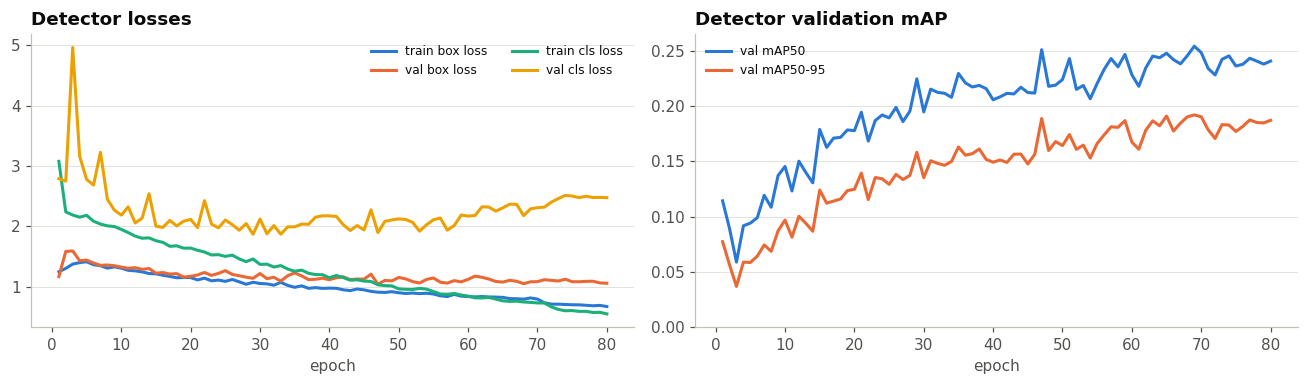

saved → /content/drive/MyDrive/CP461Project/outputs/figures/fig_det_training_curves.png


In [11]:
res = pd.read_csv(RUNS / "yolo_det/results.csv"); res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for col, lab, c in [("train/box_loss", "train box loss", "#2a78d6"), ("val/box_loss", "val box loss", "#eb6834"),
                    ("train/cls_loss", "train cls loss", "#1baf7a"), ("val/cls_loss", "val cls loss", "#eda100")]:
    if col in res:
        ax[0].plot(res["epoch"], res[col], lw=2, label=lab, color=c)
ax[0].set_title("Detector losses", loc="left"); ax[0].set_xlabel("epoch"); ax[0].legend(ncol=2, fontsize=8)
for col, lab, c in [("metrics/mAP50(B)", "val mAP50", "#2a78d6"), ("metrics/mAP50-95(B)", "val mAP50-95", "#eb6834")]:
    if col in res:
        ax[1].plot(res["epoch"], res[col], lw=2, label=lab, color=c)
ax[1].set_title("Detector validation mAP", loc="left"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, None); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("fig_det_training_curves.png")

## 5 · E1: Detector evaluation on the **test** split
Ultralytics metrics (P, R and mAP per class), then our own matching at `CONF_THRES` for the confusion matrix and accuracy.

In [12]:
det = YOLO(str(DET_BEST))
m = det.val(data=str(DET_YAML), split="test", imgsz=IMG_SIZE, batch=BATCH, device=YOLO_DEVICE,
            project=str(RUNS), name="det_test", exist_ok=True, plots=True, verbose=False)
rows = []
for j, c in enumerate(m.ap_class_index):
    p, r = float(m.box.p[j]), float(m.box.r[j])
    rows.append([CLASSES[c], int(stats.loc["test", CLASSES[c]]), p, r, 2 * p * r / (p + r + 1e-9), m.box.ap50[j], m.box.ap[j]])
mp, mr = float(m.box.mp), float(m.box.mr)
rows.append(["all", int(stats.loc["test", "objects"]), mp, mr, 2 * mp * mr / (mp + mr + 1e-9), m.box.map50, m.box.map])
det_table = pd.DataFrame(rows, columns=["class", "GT objects", "Precision", "Recall", "F1", "mAP50", "mAP50-95"]).set_index("class")
det_table[["Precision", "Recall", "F1", "mAP50", "mAP50-95"]] = det_table[["Precision", "Recall", "F1", "mAP50", "mAP50-95"]].astype(float).round(3)
det_table.to_csv(OUT / "E1_detection_metrics.csv"); display(det_table)
for f in (RUNS / "det_test").glob("*.png"):
    shutil.copy(f, FIG / f"det_test_{f.name}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2408.9±950.2 MB/s, size: 502.5 KB)
val: Scanning /content/litter_local/yolo_det/labels/test... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 2.0Kit/s 0.1s
val: New cache created: /content/litter_local/yolo_det/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.3it/s 6.6s
                   all        225        710      0.393      0.264      0.246      0.189
Speed: 2.8ms preprocess, 8.7ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/drive/MyDrive/CP461Project/runs/det_test


,GT objects,Precision,Recall,F1,mAP50,mAP50-95
class,,,,,,
Plastic,321,0.518,0.421,0.464,0.407,0.323
Paper & Cardboard,74,0.490,0.284,0.359,0.258,0.212
Metal,89,0.508,0.517,0.513,0.465,0.363
Glass,46,0.144,0.043,0.067,0.027,0.013
Other Waste,180,0.303,0.056,0.094,0.074,0.034
all,710,0.393,0.264,0.316,0.246,0.189


detector on test images:   0%|          | 0/225 [00:00<?, ?it/s]

At conf ≥ 0.25, box IoU ≥ 0.5:  classification accuracy of localised objects = 0.675 (218/323)


,TP,FP,FN,Precision,Recall,F1
Plastic,133,215,188,0.382,0.414,0.398
Paper & Cardboard,20,33,54,0.377,0.270,0.315
Metal,45,76,44,0.372,0.506,0.429
Glass,2,12,44,0.143,0.043,0.067
Other Waste,18,72,162,0.200,0.100,0.133
all (micro),218,408,492,0.348,0.307,0.326


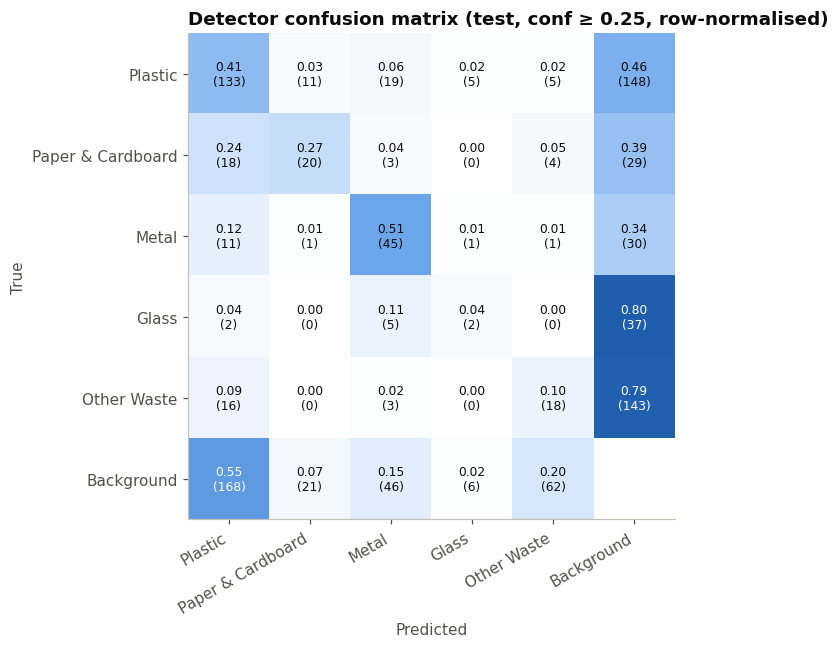

saved → /content/drive/MyDrive/CP461Project/outputs/figures/fig_confusion_matrix.png


In [13]:
# ---- predictions on the test images (kept for E3 and the figures) ----
with contextlib.redirect_stdout(io.StringIO()):
    test_coco = COCO(str(COCO_JSON["test"]))
test_ids = sorted(test_coco.getImgIds())
if MAX_TEST_IMAGES:
    test_ids = test_ids[:MAX_TEST_IMAGES]

def gt_of(i):
    anns = test_coco.loadAnns(test_coco.getAnnIds(imgIds=i))
    boxes = np.array([[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]] for a in anns],
                     np.float32).reshape(-1, 4)
    return dict(anns=anns, boxes=boxes, cls=np.array([a["category_id"] - 1 for a in anns], int),
                rles=[test_coco.annToRLE(a) for a in anns], area=np.array([a["area"] for a in anns], float))
GT = {i: gt_of(i) for i in test_ids}

det_preds = {}
paths = [str(FAST_IMG / images_all[i]["file_name"]) for i in test_ids]
# one image per call: Ultralytics turns a Python list of paths into ONE batch, which can run out of GPU memory
for i, pth in tqdm(list(zip(test_ids, paths)), desc="detector on test images"):
    r = det.predict(pth, conf=0.001, iou=0.7, max_det=100, imgsz=IMG_SIZE, device=YOLO_DEVICE, verbose=False)[0]
    det_preds[i] = dict(boxes=r.boxes.xyxy.cpu().numpy().astype(np.float32), scores=r.boxes.conf.cpu().numpy(),
                        cls=r.boxes.cls.cpu().numpy().astype(int))

def box_iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    lt = np.maximum(a[:, None, :2], b[None, :, :2]); rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None] - inter + 1e-9)

def match(pb, ps, gb, thr=MATCH_IOU):
    # Greedy class-agnostic matching, highest score first → [(pred_idx, gt_idx)], unmatched preds, unmatched GTs
    iou, used, pairs = box_iou(pb, gb), set(), []
    for p in np.argsort(-ps):
        if iou.shape[1] == 0:
            break
        cand = np.where((iou[p] >= thr) & ~np.isin(np.arange(iou.shape[1]), list(used)))[0]
        if len(cand):
            g = cand[np.argmax(iou[p, cand])]; used.add(g); pairs.append((int(p), int(g)))
    mp_ = {p for p, _ in pairs}
    return pairs, [p for p in range(len(pb)) if p not in mp_], [g for g in range(len(gb)) if g not in used]

# ---- confusion matrix + accuracy at CONF_THRES ----
nc = len(CLASSES); cm = np.zeros((nc + 1, nc + 1), int)      # rows = true (last = background), cols = predicted
per_image = {}
for i in test_ids:
    p, g = det_preds[i], GT[i]; k = p["scores"] >= CONF_THRES
    pb, ps, pc = p["boxes"][k], p["scores"][k], p["cls"][k]
    pairs, ump, umg = match(pb, ps, g["boxes"])
    for pi, gi in pairs: cm[g["cls"][gi], pc[pi]] += 1
    for pi in ump: cm[nc, pc[pi]] += 1
    for gi in umg: cm[g["cls"][gi], nc] += 1
    per_image[i] = dict(pairs=pairs, ump=ump, umg=umg, pb=pb, ps=ps, pc=pc,
                        n_ok=sum(pc[pi] == g["cls"][gi] for pi, gi in pairs), n_gt=len(g["boxes"]))
tp = np.diag(cm)[:nc]; fp = cm[:, :nc].sum(0) - tp; fn = cm[:nc, :].sum(1) - tp
P_, R_ = tp / np.maximum(tp + fp, 1), tp / np.maximum(tp + fn, 1)
thr_table = pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "Precision": P_, "Recall": R_,
                          "F1": 2 * P_ * R_ / np.maximum(P_ + R_, 1e-9)}, index=CLASSES)
matched = cm[:nc, :nc].sum()
cls_acc = np.trace(cm[:nc, :nc]) / max(matched, 1)
thr_table.loc["all (micro)"] = [tp.sum(), fp.sum(), fn.sum(), tp.sum() / max(tp.sum() + fp.sum(), 1),
                                tp.sum() / max(tp.sum() + fn.sum(), 1), 0]
thr_table.loc["all (micro)", "F1"] = 2 * thr_table.loc["all (micro)", "Precision"] * thr_table.loc["all (micro)", "Recall"] / max(
    thr_table.loc["all (micro)", "Precision"] + thr_table.loc["all (micro)", "Recall"], 1e-9)
thr_table = thr_table.round(3); thr_table[["TP", "FP", "FN"]] = thr_table[["TP", "FP", "FN"]].astype(int)
thr_table.to_csv(OUT / "E1_detection_at_conf_thres.csv")
print(f"At conf ≥ {CONF_THRES}, box IoU ≥ {MATCH_IOU}:  classification accuracy of localised objects = {cls_acc:.3f} "
      f"({np.trace(cm[:nc, :nc])}/{matched})")
display(thr_table)

labels = CLASSES + ["Background"]
norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("blue", ["#ffffff", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
fig, ax = plt.subplots(figsize=(7.2, 6))
ax.imshow(norm, cmap=cmap, vmin=0, vmax=1); ax.grid(False)
for r_ in range(nc + 1):
    for c_ in range(nc + 1):
        if r_ == nc and c_ == nc:
            continue
        ax.text(c_, r_, f"{norm[r_, c_]:.2f}\n({cm[r_, c_]})", ha="center", va="center", fontsize=8,
                color="white" if norm[r_, c_] > 0.55 else INK)
ax.set_xticks(range(nc + 1), labels, rotation=30, ha="right"); ax.set_yticks(range(nc + 1), labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Detector confusion matrix (test, conf ≥ {CONF_THRES}, row-normalised)", loc="left")
plt.tight_layout(); savefig("fig_confusion_matrix.png")

## 6 · EfficientSAM: load Ti and S, segment from box prompts
A box is passed to EfficientSAM as two points with labels **2 (top-left)** and **3 (bottom-right)**. The image is encoded once per image, then all boxes are decoded in batches. Of the 3 candidate masks, we keep the one with the highest predicted IoU.

In [14]:
sys.path.insert(0, str(REPOS / "EfficientSAM"))
from efficient_sam.efficient_sam import build_efficient_sam

SAM_NAME = {"ti": "EfficientSAM-Ti", "s": "EfficientSAM-S"}

def load_esam(variant):
    wdir = REPOS / "EfficientSAM/weights"
    if variant == "s":
        if not (wdir / "efficient_sam_vits.pt").exists():
            with zipfile.ZipFile(wdir / "efficient_sam_vits.pt.zip") as z:
                z.extractall(wdir)
        dim, heads, ckpt = 384, 6, wdir / "efficient_sam_vits.pt"
    else:
        dim, heads, ckpt = 192, 3, wdir / "efficient_sam_vitt.pt"
    model = build_efficient_sam(encoder_patch_embed_dim=dim, encoder_num_heads=heads, checkpoint=None)
    model.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=False)["model"])
    return model.eval().to(DEVICE)

ESAM = {v: load_esam(v) for v in SAM_VARIANTS}
PARAMS = {SAM_NAME[v]: sum(p.numel() for p in mdl.parameters()) / 1e6 for v, mdl in ESAM.items()}
PARAMS["YOLO detector"] = sum(p.numel() for p in det.model.parameters()) / 1e6
for k, v in PARAMS.items():
    print(f"{k:16s} {v:6.1f} M parameters")

def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

@torch.inference_mode()
def esam_embed(model, img):
    x = torch.from_numpy(img).permute(2, 0, 1).float().div(255).unsqueeze(0).to(DEVICE)
    return model.get_image_embeddings(x)

@torch.inference_mode()
def esam_decode(model, emb, boxes, H, W, chunk=32):
    # boxes: N×4 xyxy in pixels → N×H×W boolean masks
    out = []
    for k in range(0, len(boxes), chunk):
        b = torch.as_tensor(np.asarray(boxes[k:k + chunk]), dtype=torch.float32, device=DEVICE)
        n = b.shape[0]
        pts = b.view(1, n, 2, 2)
        lbl = torch.tensor([2, 3], device=DEVICE).view(1, 1, 2).expand(1, n, 2)
        logits, iou = model.predict_masks(emb, pts, lbl, multimask_output=True, input_h=H, input_w=W,
                                          output_h=-1, output_w=-1)
        low = logits[0, torch.arange(n, device=DEVICE), iou[0].argmax(-1)]          # n×256×256
        out.append((F.interpolate(low[:, None], (H, W), mode="bicubic")[:, 0] >= 0).cpu().numpy())
    return np.concatenate(out) if out else np.zeros((0, H, W), bool)

def to_rle(mk):
    r = mask_utils.encode(np.asfortranarray(mk.astype(np.uint8)))
    r["counts"] = r["counts"].decode()
    return r

def rle_iou(a, b):
    return float(mask_utils.iou([a], [b], [0])[0, 0])

# warm-up (so the first timed image is not slower)
for v in SAM_VARIANTS:
    e = esam_embed(ESAM[v], np.zeros((480, 640, 3), np.uint8)); esam_decode(ESAM[v], e, np.array([[10, 10, 200, 200]]), 480, 640)
print("✓ EfficientSAM ready")

EfficientSAM-Ti    10.2 M parameters
EfficientSAM-S     26.4 M parameters
YOLO detector       9.4 M parameters
✓ EfficientSAM ready


## 7 · E2 + E3: segmentation from GT boxes and from YOLO boxes
* **E2 (GT box prompts):** measures EfficientSAM alone, with a perfect box. IoU and Dice per object.
* **E3 (YOLO box prompts):** the real pipeline. COCO mask AP over all detections; IoU and Dice on detections matched to a GT object at `CONF_THRES`.

In [15]:
free_gpu()
e2_rows, e3_rows, rles_e2 = [], [], {}
det_results, seg_results = [], {v: [] for v in SAM_VARIANTS}
enc_ms = {v: [] for v in SAM_VARIANTS}

def size_bin(a):
    return "small" if a < 32 ** 2 else ("medium" if a < 96 ** 2 else "large")

for i in tqdm(test_ids, desc="EfficientSAM on test images"):
    img = load_rgb(i); H, W = img.shape[:2]; g, p, pi_ = GT[i], det_preds[i], per_image[i]
    for b, s, c in zip(p["boxes"], p["scores"], p["cls"]):
        det_results.append({"image_id": i, "category_id": int(c) + 1, "score": float(s),
                            "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]})
    keep_idx = np.where(p["scores"] >= CONF_THRES)[0]
    for v in SAM_VARIANTS:
        model = ESAM[v]
        sync(); t0 = time.perf_counter(); emb = esam_embed(model, img); sync(); enc_ms[v].append((time.perf_counter() - t0) * 1000)
        # E2: ground-truth boxes
        if len(g["boxes"]):
            for k, mk in enumerate(esam_decode(model, emb, g["boxes"], H, W)):
                r = to_rle(mk); iou = rle_iou(r, g["rles"][k]); rles_e2[(i, k, v)] = r
                e2_rows.append(dict(image_id=i, gt_idx=k, method=SAM_NAME[v], cls=CLASSES[g["cls"][k]], area=g["area"][k],
                                    size=size_bin(g["area"][k]), iou=iou, dice=2 * iou / (1 + iou)))
        # E3: YOLO boxes (all detections for mask AP; matched ones for IoU/Dice)
        if len(p["boxes"]):
            rl = [to_rle(mk) for mk in esam_decode(model, emb, p["boxes"], H, W)]
            for r, s, c in zip(rl, p["scores"], p["cls"]):
                seg_results[v].append({"image_id": i, "category_id": int(c) + 1, "segmentation": r, "score": float(s)})
            for pk, gk in pi_["pairs"]:
                j = keep_idx[pk]; iou = rle_iou(rl[j], g["rles"][gk])
                e3_rows.append(dict(image_id=i, gt_idx=gk, method=SAM_NAME[v], cls=CLASSES[g["cls"][gk]], size=size_bin(g["area"][gk]),
                                    iou=iou, dice=2 * iou / (1 + iou), box_iou=float(box_iou(p["boxes"][j:j + 1], g["boxes"][gk:gk + 1])[0, 0]),
                                    class_ok=bool(p["cls"][j] == g["cls"][gk])))
e2 = pd.DataFrame(e2_rows); e3 = pd.DataFrame(e3_rows)
e2.to_csv(OUT / "E2_gt_box_per_object.csv", index=False); e3.to_csv(OUT / "E3_yolo_box_matched_per_object.csv", index=False)
print(f"E2: {len(e2)} object masks · E3: {len(det_results)} detections, {len(e3)} matched masks")

EfficientSAM on test images:   0%|          | 0/225 [00:00<?, ?it/s]

E2: 1420 object masks · E3: 14222 detections, 646 matched masks


## 8 · E4: YOLO-seg baseline + COCO mask AP for every method

In [16]:
def coco_eval(results, iou_type):
    if not results:
        return np.zeros(12), None
    with contextlib.redirect_stdout(io.StringIO()):
        dt = test_coco.loadRes([dict(r) for r in results])
        E = COCOeval(test_coco, dt, iou_type); E.params.imgIds = test_ids
        E.evaluate(); E.accumulate(); E.summarize()
    return E.stats, E

def per_class_ap(E):
    out = {}
    for k, cid in enumerate(E.params.catIds):
        pr = E.eval["precision"][:, :, k, 0, -1]; pr = pr[pr > -1]
        out[CLASSES[cid - 1]] = float(pr.mean()) if pr.size else float("nan")
    return out

free_gpu()
yseg_results, e4_rows = [], []
if SEG_BEST is not None:
    segm = YOLO(str(SEG_BEST))
    for i, pth in tqdm(list(zip(test_ids, paths)), desc="YOLO-seg"):      # one image per call (see E1)
        r = segm.predict(pth, conf=0.001, iou=0.7, max_det=100, imgsz=IMG_SIZE, retina_masks=True,
                         device=YOLO_DEVICE, verbose=False)[0]
        if r.masks is None or len(r.boxes) == 0:
            continue
        H, W = r.orig_shape; g = GT[i]
        md_ = r.masks.data
        if tuple(md_.shape[-2:]) != (H, W):
            md_ = F.interpolate(md_[:, None].float(), (H, W), mode="nearest")[:, 0]
        mks = (md_ > 0.5).cpu().numpy()
        sc, cl, bx = r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int), r.boxes.xyxy.cpu().numpy()
        rl = [to_rle(mk) for mk in mks]
        for rr, s, c in zip(rl, sc, cl):
            yseg_results.append({"image_id": i, "category_id": int(c) + 1, "segmentation": rr, "score": float(s)})
        k = np.where(sc >= CONF_THRES)[0]
        pairs, _, _ = match(bx[k], sc[k], g["boxes"])
        for pk, gk in pairs:
            iou = rle_iou(rl[k[pk]], g["rles"][gk])
            e4_rows.append(dict(image_id=i, gt_idx=gk, method="YOLO-seg", cls=CLASSES[g["cls"][gk]], size=size_bin(g["area"][gk]),
                                iou=iou, dice=2 * iou / (1 + iou), class_ok=bool(cl[k[pk]] == g["cls"][gk])))
e4 = pd.DataFrame(e4_rows)

box_stats, _ = coco_eval(det_results, "bbox")
SEG_EVAL = {SAM_NAME[v]: coco_eval(seg_results[v], "segm") for v in SAM_VARIANTS}
if yseg_results:
    SEG_EVAL["YOLO-seg"] = coco_eval(yseg_results, "segm")
print(f"Detector box AP (pycocotools): AP={box_stats[0]:.3f}  AP50={box_stats[1]:.3f}  AP75={box_stats[2]:.3f}")
for k, (st, _) in SEG_EVAL.items():
    print(f"{k:16s} mask AP={st[0]:.3f}  AP50={st[1]:.3f}  AP75={st[2]:.3f}  AP_small={st[3]:.3f}  AP_medium={st[4]:.3f}  AP_large={st[5]:.3f}")

YOLO-seg:   0%|          | 0/225 [00:00<?, ?it/s]

Detector box AP (pycocotools): AP=0.181  AP50=0.232  AP75=0.193
EfficientSAM-Ti  mask AP=0.180  AP50=0.233  AP75=0.189  AP_small=0.014  AP_medium=0.222  AP_large=0.280
EfficientSAM-S   mask AP=0.184  AP50=0.235  AP75=0.193  AP_small=0.015  AP_medium=0.227  AP_large=0.288
YOLO-seg         mask AP=0.142  AP50=0.218  AP75=0.153  AP_small=0.012  AP_medium=0.167  AP_large=0.233


## 9 · E5: speed benchmark (end-to-end ms per image)

In [17]:
timing_ids = test_ids[:TIMING_IMAGES]
def bench(fn):
    for i in timing_ids[:3]:
        fn(load_rgb(i))                                  # warm-up
    ts = []
    for i in timing_ids:
        img = load_rgb(i); sync(); t0 = time.perf_counter(); fn(img); sync(); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(ts))

def run_det(img):
    # agnostic NMS: one label per object, so the litter count is not inflated by overlapping boxes of different classes
    r = det.predict(np.ascontiguousarray(img[..., ::-1]), conf=CONF_THRES, imgsz=IMG_SIZE, device=YOLO_DEVICE,
                    agnostic_nms=True, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy()

def make_pipeline(v):
    def fn(img):
        boxes, cls, sc = run_det(img)
        H, W = img.shape[:2]
        masks = esam_decode(ESAM[v], esam_embed(ESAM[v], img), boxes, H, W) if len(boxes) else np.zeros((0, H, W), bool)
        return boxes, cls, sc, masks
    return fn

SPEED = {"YOLO detector only": bench(run_det)}
for v in SAM_VARIANTS:
    SPEED[f"YOLO + {SAM_NAME[v]}"] = bench(make_pipeline(v))
if SEG_BEST is not None:
    SPEED["YOLO-seg"] = bench(lambda img: segm.predict(np.ascontiguousarray(img[..., ::-1]), conf=CONF_THRES, imgsz=IMG_SIZE,
                                                       retina_masks=True, device=YOLO_DEVICE, verbose=False))
for k, v in SPEED.items():
    print(f"{k:24s} {v:7.1f} ms / image")
print({SAM_NAME[v]: f"encoder {np.mean(enc_ms[v]):.1f} ms" for v in SAM_VARIANTS})

YOLO detector only          24.6 ms / image
YOLO + EfficientSAM-Ti     160.1 ms / image
YOLO + EfficientSAM-S      291.6 ms / image
YOLO-seg                    22.5 ms / image
{'EfficientSAM-Ti': 'encoder 119.9 ms', 'EfficientSAM-S': 'encoder 262.7 ms'}


## 10 · Results tables

In [18]:
rows = []
for v in SAM_VARIANTS:
    n = SAM_NAME[v]; d2 = e2[e2.method == n]
    rows.append([f"GT box → {n}", "oracle box", np.nan, np.nan, np.nan, d2.iou.mean(), d2.dice.mean(), (d2.iou >= 0.5).mean(),
                 np.nan, PARAMS[n]])
for v in SAM_VARIANTS:
    n = SAM_NAME[v]; st = SEG_EVAL[n][0]; d3 = e3[e3.method == n] if len(e3) else e3
    rows.append([f"YOLO box → {n}", "predicted box", st[0], st[1], st[2],
                 d3.iou.mean() if len(d3) else np.nan, d3.dice.mean() if len(d3) else np.nan,
                 (d3.iou >= 0.5).mean() if len(d3) else np.nan, SPEED[f"YOLO + {n}"], PARAMS[n] + PARAMS["YOLO detector"]])
if "YOLO-seg" in SEG_EVAL:
    st = SEG_EVAL["YOLO-seg"][0]
    rows.append(["YOLO-seg (one-stage)", "—", st[0], st[1], st[2], e4.iou.mean() if len(e4) else np.nan,
                 e4.dice.mean() if len(e4) else np.nan, (e4.iou >= 0.5).mean() if len(e4) else np.nan, SPEED["YOLO-seg"],
                 sum(p.numel() for p in segm.model.parameters()) / 1e6])
main_table = pd.DataFrame(rows, columns=["Method", "Prompt", "Mask AP", "Mask AP50", "Mask AP75", "mIoU", "mDice",
                                         "IoU≥0.5 rate", "ms / image", "Params (M)"]).set_index("Method")
main_table = main_table.round(3); main_table.to_csv(OUT / "TABLE_main_segmentation_results.csv")
print("Main comparison (test split). mIoU/mDice: E2 = all GT objects; E3/E4 = detections matched at conf ≥", CONF_THRES)
display(main_table)

e2_cls = e2.pivot_table(index="cls", columns="method", values="iou", aggfunc="mean").reindex(CLASSES)
e2_size = e2.pivot_table(index="size", columns="method", values="iou", aggfunc="mean").reindex(["small", "medium", "large"])
e2_size["objects"] = e2[e2.method == SAM_NAME[SAM_VARIANTS[0]]].groupby("size").size().reindex(e2_size.index)
ap_cls = pd.DataFrame({k: per_class_ap(E) for k, (st, E) in SEG_EVAL.items() if E is not None}).reindex(CLASSES)
for name, t in [("TABLE_E2_iou_by_class", e2_cls), ("TABLE_E2_iou_by_size", e2_size), ("TABLE_mask_AP_by_class", ap_cls)]:
    t.round(3).to_csv(OUT / f"{name}.csv"); print(name); display(t.round(3))

Main comparison (test split). mIoU/mDice: E2 = all GT objects; E3/E4 = detections matched at conf ≥ 0.25


,Prompt,Mask AP,Mask AP50,Mask AP75,mIoU,mDice,IoU≥0.5 rate,ms / image,Params (M)
Method,,,,,,,,,
GT box → EfficientSAM-Ti,oracle box,NaN,NaN,NaN,0.781,0.863,0.901,NaN,10.223
GT box → EfficientSAM-S,oracle box,NaN,NaN,NaN,0.787,0.867,0.903,NaN,26.413
YOLO box → EfficientSAM-Ti,predicted box,0.180,0.233,0.189,0.877,0.929,0.978,160.131,19.653
YOLO box → EfficientSAM-S,predicted box,0.184,0.235,0.193,0.884,0.933,0.991,291.578,35.843
YOLO-seg (one-stage),—,0.142,0.218,0.153,0.832,0.902,0.971,22.525,10.084


TABLE_E2_iou_by_class


method,EfficientSAM-S,EfficientSAM-Ti
cls,,
Plastic,0.820,0.807
Paper & Cardboard,0.901,0.885
Metal,0.831,0.832
Glass,0.719,0.735
Other Waste,0.677,0.678


TABLE_E2_iou_by_size


method,EfficientSAM-S,EfficientSAM-Ti,objects
size,,,
small,0.656,0.660,306
medium,0.859,0.843,238
large,0.926,0.914,166


TABLE_mask_AP_by_class


,EfficientSAM-Ti,EfficientSAM-S,YOLO-seg
Plastic,0.299,0.307,0.253
Paper & Cardboard,0.212,0.217,0.133
Metal,0.353,0.362,0.286
Glass,0.012,0.013,0.007
Other Waste,0.024,0.022,0.030


## 11 · Result charts

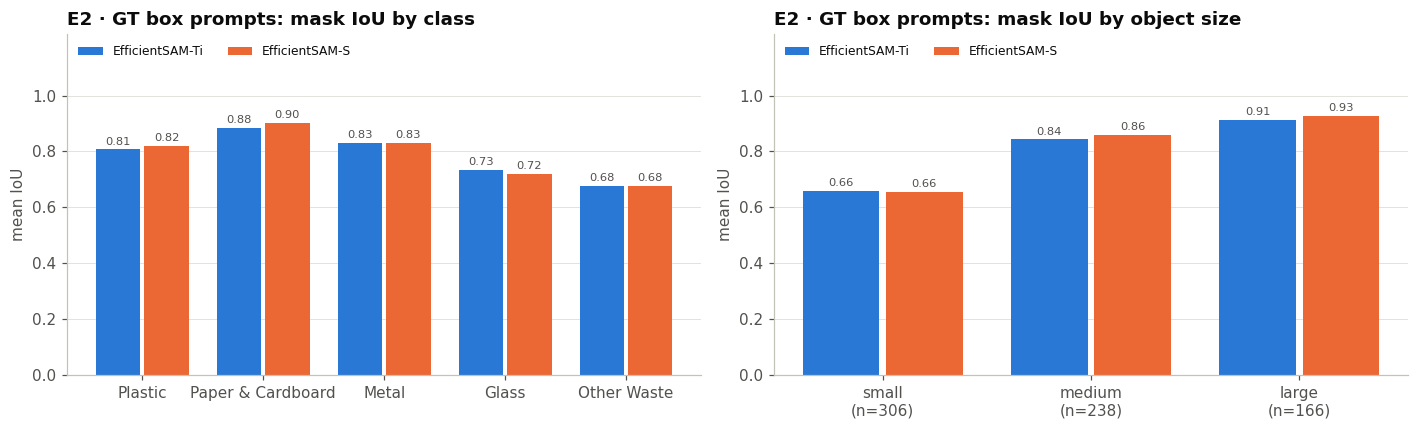

saved → /content/drive/MyDrive/CP461Project/outputs/figures/fig_E2_iou_by_class_and_size.png


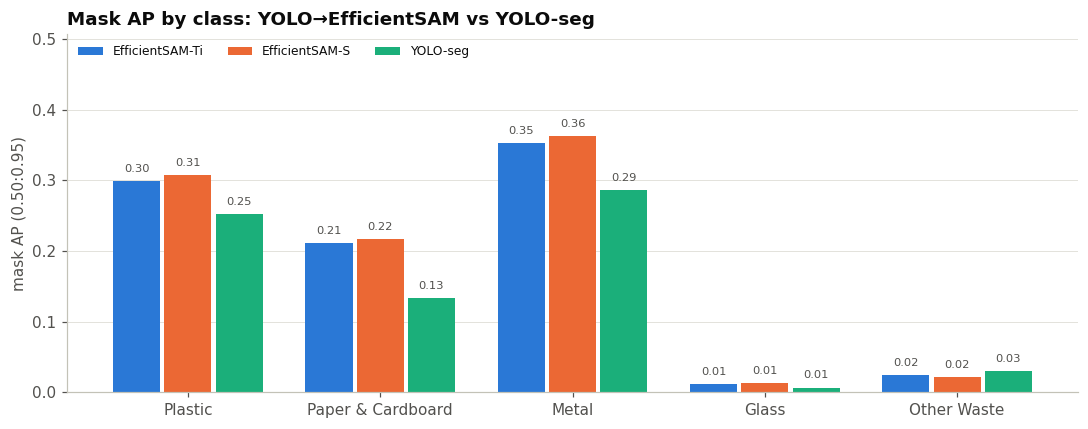

saved → /content/drive/MyDrive/CP461Project/outputs/figures/fig_mask_AP_by_class.png


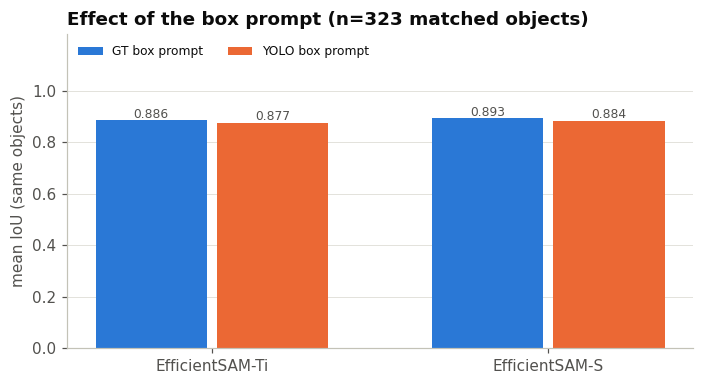

saved → /content/drive/MyDrive/CP461Project/outputs/figures/fig_E3_gt_vs_yolo_prompt.png


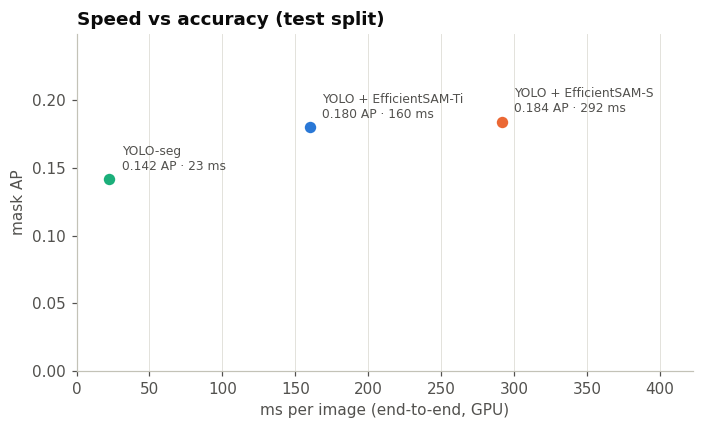

saved → /content/drive/MyDrive/CP461Project/outputs/figures/fig_speed_vs_accuracy.png


In [19]:
def grouped_bars(ax, table, methods, ylabel, title, ylim=(0, 1)):
    x = np.arange(len(table.index)); w = 0.8 / len(methods)
    for k, mth in enumerate(methods):
        vals = table[mth].values
        bars = ax.bar(x + (k - (len(methods) - 1) / 2) * w, vals, w * 0.92, label=mth, color=METHOD_COLORS[mth])
        for b_, v_ in zip(bars, vals):
            if not np.isnan(v_):
                ax.text(b_.get_x() + b_.get_width() / 2, v_ + 0.01, f"{v_:.2f}", ha="center", va="bottom", fontsize=7.5, color=INK2)
    ax.set_xticks(x, table.index, rotation=0); ax.set_ylim(*ylim); ax.set_ylabel(ylabel); ax.set_title(title, loc="left")
    if ylim[1] > 1:                                   # headroom above 1.0 is only for the legend
        ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.legend(fontsize=8, ncol=len(methods), loc="upper left")

sam_methods = [SAM_NAME[v] for v in SAM_VARIANTS]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
grouped_bars(ax[0], e2_cls, sam_methods, "mean IoU", "E2 · GT box prompts: mask IoU by class", (0, 1.22))
grouped_bars(ax[1], e2_size.drop(columns="objects"), sam_methods, "mean IoU", "E2 · GT box prompts: mask IoU by object size", (0, 1.22))
ax[1].set_xticks(range(3), [f"{s}\n(n={int(n)})" for s, n in zip(e2_size.index, e2_size["objects"].fillna(0))])
plt.tight_layout(); savefig("fig_E2_iou_by_class_and_size.png")

fig, ax = plt.subplots(figsize=(10, 4))
grouped_bars(ax, ap_cls, list(ap_cls.columns), "mask AP (0.50:0.95)", "Mask AP by class: YOLO→EfficientSAM vs YOLO-seg", (0, min(1.0, max(0.1, np.nanmax(ap_cls.values) * 1.4))))
plt.tight_layout(); savefig("fig_mask_AP_by_class.png")

# prompt quality: GT box vs YOLO box (same objects only)
if len(e3):
    both = e3.merge(e2, on=["image_id", "gt_idx", "method"], suffixes=("_yolo", "_gt"))
    comp = both.groupby("method")[["iou_gt", "iou_yolo"]].mean().reindex(sam_methods)
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    x = np.arange(len(comp)); w = 0.36
    for k, (col, lab, c) in enumerate([("iou_gt", "GT box prompt", "#2a78d6"), ("iou_yolo", "YOLO box prompt", "#eb6834")]):
        bars = ax.bar(x + (k - 0.5) * w, comp[col], w * 0.92, label=lab, color=c)
        for b_, v_ in zip(bars, comp[col]):
            ax.text(b_.get_x() + b_.get_width() / 2, v_ + 0.01, f"{v_:.3f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(x, comp.index); ax.set_ylim(0, 1.22); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.set_ylabel("mean IoU (same objects)")
    ax.set_title(f"Effect of the box prompt (n={len(both) // max(len(sam_methods), 1)} matched objects)", loc="left"); ax.legend(fontsize=8, ncol=2, loc="upper left")
    plt.tight_layout(); savefig("fig_E3_gt_vs_yolo_prompt.png")
    comp.round(3).to_csv(OUT / "TABLE_E3_gt_vs_yolo_prompt.csv")

# speed vs accuracy
pts = [(f"YOLO + {SAM_NAME[v]}", SPEED[f"YOLO + {SAM_NAME[v]}"], SEG_EVAL[SAM_NAME[v]][0][0], METHOD_COLORS[SAM_NAME[v]]) for v in SAM_VARIANTS]
if "YOLO-seg" in SEG_EVAL:
    pts.append(("YOLO-seg", SPEED["YOLO-seg"], SEG_EVAL["YOLO-seg"][0][0], METHOD_COLORS["YOLO-seg"]))
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, ms, ap, c in pts:
    ax.scatter(ms, ap, s=90, color=c, edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"{name}\n{ap:.3f} AP · {ms:.0f} ms", (ms, ap), textcoords="offset points", xytext=(8, 6), fontsize=8, color=INK2)
ax.grid(axis="both"); ax.set_xlabel("ms per image (end-to-end, " + ("GPU" if DEVICE == "cuda" else "CPU") + ")"); ax.set_ylabel("mask AP")
ax.set_xlim(0, max(p[1] for p in pts) * 1.45); ax.set_ylim(0, max(0.05, max(p[2] for p in pts) * 1.35))
ax.set_title("Speed vs accuracy (test split)", loc="left")
plt.tight_layout(); savefig("fig_speed_vs_accuracy.png")

## 12 · Qualitative results: correct and incorrect predictions

In [20]:
def crop_box(b, H, W, pad=0.3, mn=40):
    x0, y0, x1, y1 = b; w, h = x1 - x0, y1 - y0; p = pad * max(w, h) + 8
    return int(max(0, x0 - p)), int(max(0, y0 - p)), int(min(W, x1 + p)), int(min(H, y1 + p))

# ---- EfficientSAM best / worst masks (GT box prompts) ----
ref = SAM_NAME[SAM_VARIANTS[-1]]
cand = e2[(e2.method == ref) & (e2.area >= 40 ** 2)].sort_values("iou")
picks = list(cand.itertuples())[::-1] if len(cand) <= 8 else list(cand.tail(4).itertuples())[::-1] + list(cand.head(4).itertuples())
if picks:
    fig, axes = plt.subplots(1 + len(SAM_VARIANTS), len(picks), figsize=(2.1 * len(picks), 2.2 * (1 + len(SAM_VARIANTS))))
    axes = np.atleast_2d(axes)
    for j, rw in enumerate(picks):
        img = load_rgb(rw.image_id); H, W = img.shape[:2]; g = GT[rw.image_id]
        x0, y0, x1, y1 = crop_box(g["boxes"][rw.gt_idx], H, W)
        gt_mask = mask_utils.decode(g["rles"][rw.gt_idx]).astype(bool)
        panels = [("GT", gt_mask, "#ffffff")] + [(SAM_NAME[v], mask_utils.decode(rles_e2[(rw.image_id, rw.gt_idx, v)]).astype(bool), METHOD_COLORS[SAM_NAME[v]]) for v in SAM_VARIANTS]
        for r_, (nm, mk, col) in enumerate(panels):
            a_ = axes[r_, j]; a_.axis("off")
            vis = overlay(img, mk, col if nm != "GT" else "#1baf7a")
            bx = g["boxes"][rw.gt_idx].astype(int); cv2.rectangle(vis, tuple(bx[:2]), tuple(bx[2:]), (255, 255, 255), 2)
            a_.imshow(vis[y0:y1, x0:x1])
            if nm == "GT":
                tag = "✓ good" if rw.iou >= 0.75 else ("✗ bad" if rw.iou < 0.5 else "~ fair")
                a_.set_title(f"{tag} · {rw.cls}", fontsize=8, color=INK)
            else:
                iou = e2[(e2["image_id"] == rw.image_id) & (e2["gt_idx"] == rw.gt_idx) & (e2["method"] == nm)]["iou"].iloc[0]
                a_.set_title(f"{nm.replace('EfficientSAM', 'ESAM')}  IoU {iou:.2f}", fontsize=8, color=INK2)
    plt.suptitle("EfficientSAM masks from GT box prompts: 4 best vs 4 worst objects (≥40×40 px)", fontweight="bold", y=1.01)
    plt.tight_layout(); savefig("fig_E2_good_vs_bad_masks.png")

# ---- detector: correct vs incorrect images ----
def draw_det(img, i):
    vis = img.copy(); pim, g = per_image[i], GT[i]
    fs, th = 0.55 * max(1.0, img.shape[1] / 700), max(2, round(img.shape[1] / 450))
    matched_p = {p: gk for p, gk in pim["pairs"]}
    for p in range(len(pim["pb"])):
        b = pim["pb"][p].astype(int); c = pim["pc"][p]
        if p in matched_p and c == g["cls"][matched_p[p]]:
            col, txt = (12, 163, 12), CLASSES[c]                        # correct
        elif p in matched_p:
            col, txt = (208, 59, 59), f"{CLASSES[c]} (true: {CLASSES[g['cls'][matched_p[p]]]})"   # wrong class
        else:
            col, txt = (208, 59, 59), f"FP {CLASSES[c]}"                # false positive
        cv2.rectangle(vis, tuple(b[:2]), tuple(b[2:]), col, th + 1)
        cv2.putText(vis, txt, (b[0], max(int(25 * fs), b[1] - 6)), cv2.FONT_HERSHEY_SIMPLEX, fs, col, th, cv2.LINE_AA)
    for gk in pim["umg"]:
        b = g["boxes"][gk].astype(int)
        cv2.rectangle(vis, tuple(b[:2]), tuple(b[2:]), (250, 178, 25), th + 1)
        cv2.putText(vis, f"missed {CLASSES[g['cls'][gk]]}", (b[0], max(int(25 * fs), b[1] - 6)), cv2.FONT_HERSHEY_SIMPLEX, fs, (250, 178, 25), th, cv2.LINE_AA)
    return vis

scored = []
for i in test_ids:
    pim = per_image[i]; errs = len(pim["ump"]) + len(pim["umg"]) + (len(pim["pairs"]) - pim["n_ok"])
    scored.append((errs, pim["n_ok"], i))
good = [i for e, n, i in sorted(scored, key=lambda t: (t[0], -t[1])) if e == 0 and n > 0][:3]
bad = [i for e, n, i in sorted(scored, key=lambda t: -t[0]) if e > 0][:3]
sel = [(i, "✓ all correct") for i in good] + [(i, "✗ contains errors") for i in bad]
if sel:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5)); axes = axes.ravel()
    for a_ in axes: a_.axis("off")
    for a_, (i, t) in zip(axes, sel):
        a_.imshow(draw_det(load_rgb(i), i)); a_.set_title(t, loc="left", fontsize=11)
    plt.suptitle(f"Detector on test images (conf ≥ {CONF_THRES}) · green = correct · red = wrong class / false positive · yellow = missed",
                 fontweight="bold", y=1.0)
    plt.tight_layout(); savefig("fig_detection_correct_vs_wrong.png")

Output hidden; open in https://colab.research.google.com to view.

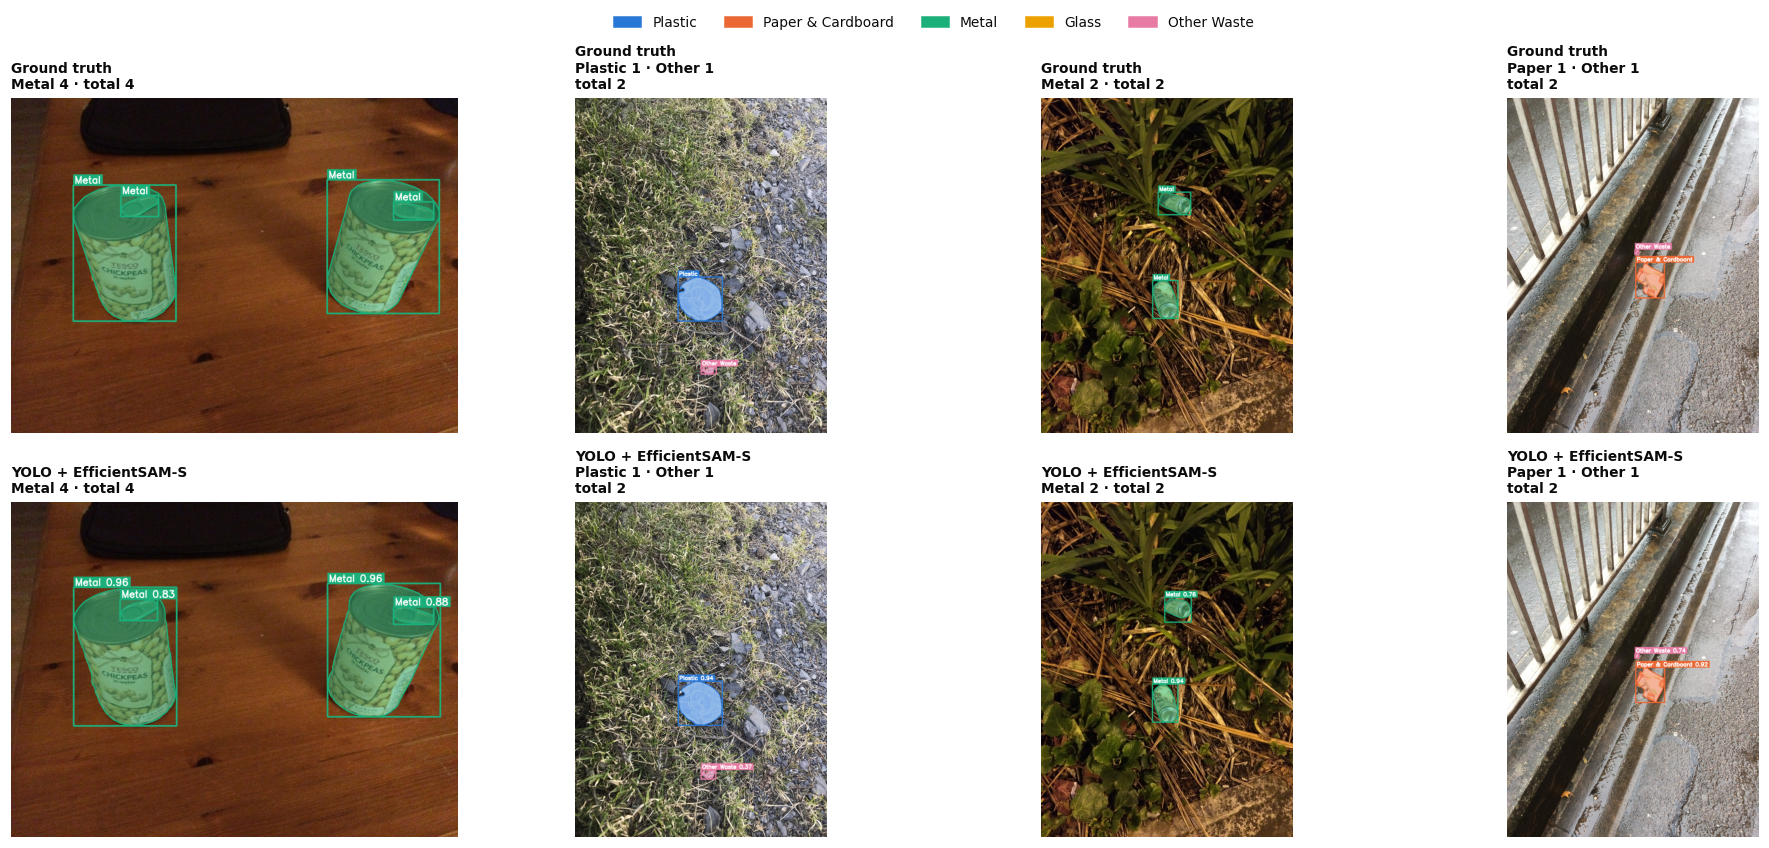

saved → /content/drive/MyDrive/CP461Project/outputs/figures/fig_pipeline_examples.png


In [21]:
# ---- full pipeline output: what the prototype shows ----
def draw_instances(img, boxes, cls, scores, masks):
    vis = img.copy()
    fs, th = 0.5 * max(1.0, img.shape[1] / 700), max(1, round(img.shape[1] / 600))
    for b, c, s, mk in sorted(zip(boxes, cls, scores, masks), key=lambda t: -t[3].sum()):   # big masks first
        vis = overlay(vis, mk, CLASS_COLORS[c], alpha=0.5)
        b = np.asarray(b).astype(int); col = hex2rgb(CLASS_COLORS[c])
        cv2.rectangle(vis, tuple(b[:2]), tuple(b[2:]), col, th + 1)
        lab = CLASSES[c] if s is None else f"{CLASSES[c]} {s:.2f}"
        (tw, tht), _ = cv2.getTextSize(lab, cv2.FONT_HERSHEY_SIMPLEX, fs, th)
        cv2.rectangle(vis, (b[0], max(0, b[1] - tht - 10)), (b[0] + tw + 8, max(tht + 10, b[1])), col, -1)
        cv2.putText(vis, lab, (b[0] + 4, max(tht + 4, b[1] - 5)), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th, cv2.LINE_AA)
    return vis

SHORT = {"Plastic": "Plastic", "Paper & Cardboard": "Paper", "Metal": "Metal", "Glass": "Glass", "Other Waste": "Other"}
def count_text(cls):
    c = Counter(CLASSES[k] for k in cls)
    items = [f"{SHORT[k]} {c[k]}" for k in CLASSES if c[k]] + [f"total {len(cls)}"]
    return "\n".join(" · ".join(items[k:k + 2]) for k in range(0, len(items), 2))   # 2 per line, fits narrow photos

pipe = make_pipeline(SAM_VARIANTS[-1])
show = [i for _, _, i in sorted(scored, key=lambda t: (t[0], -t[1]))[:4]]
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(4.4 * len(show), 7.5)); axes = np.atleast_2d(axes).reshape(2, -1)
    for j, i in enumerate(show):
        img = load_rgb(i); g = GT[i]; H, W = img.shape[:2]
        gt_masks = [mask_utils.decode(r).astype(bool) for r in g["rles"]]
        axes[0, j].imshow(draw_instances(img, g["boxes"], g["cls"], [None] * len(g["cls"]), gt_masks)); axes[0, j].axis("off")
        axes[0, j].set_title("Ground truth\n" + count_text(g["cls"]), fontsize=9, loc="left")
        boxes, cls, sc, masks = pipe(img)
        axes[1, j].imshow(draw_instances(img, boxes, cls, sc, masks)); axes[1, j].axis("off")
        axes[1, j].set_title(f"YOLO + {SAM_NAME[SAM_VARIANTS[-1]]}\n" + count_text(cls), fontsize=9, loc="left")
    handles = [matplotlib.patches.Patch(color=c, label=n) for n, c in zip(CLASSES, CLASS_COLORS)]
    fig.legend(handles=handles, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.03), fontsize=9)
    plt.tight_layout(); savefig("fig_pipeline_examples.png")

## 13 · Summary for the slides + download everything

In [22]:
best_sam = max((SAM_NAME[v] for v in SAM_VARIANTS), key=lambda n: SEG_EVAL[n][0][0])
lines = ["# Results summary (auto-generated)", "",
         f"- Test split: {len(test_ids)} images, {sum(len(GT[i]['cls']) for i in test_ids)} objects; detector `{DET_MODEL}` at {IMG_SIZE}px, {EPOCHS} epochs max",
         f"- Detector (test): P={det_table.loc['all','Precision']:.3f}  R={det_table.loc['all','Recall']:.3f}  F1={det_table.loc['all','F1']:.3f}  "
         f"mAP50={det_table.loc['all','mAP50']:.3f}  mAP50-95={det_table.loc['all','mAP50-95']:.3f}",
         f"- Classification accuracy of localised objects (conf ≥ {CONF_THRES}): {cls_acc:.3f}",
         f"- E2 GT-box mIoU: " + ", ".join(f"{SAM_NAME[v]} {e2[e2.method == SAM_NAME[v]].iou.mean():.3f}" for v in SAM_VARIANTS),
         f"- E3 pipeline mask AP: " + ", ".join(f"{k} {st[0]:.3f}" for k, (st, _) in SEG_EVAL.items()),
         f"- Best EfficientSAM variant on mask AP: {best_sam}",
         f"- Speed: " + ", ".join(f"{k} {v:.0f} ms" for k, v in SPEED.items()), ""]
def md_table(df):
    try:
        return df.to_markdown()
    except Exception:
        return "```\n" + df.to_string() + "\n```"
for title, df in [("E1 detection (Ultralytics, test)", det_table), (f"E1 detection at conf ≥ {CONF_THRES}", thr_table),
                  ("Main segmentation comparison", main_table), ("E2 mean IoU by class (GT boxes)", e2_cls.round(3)),
                  ("E2 mean IoU by object size (GT boxes)", e2_size.round(3)), ("Mask AP by class", ap_cls.round(3))]:
    lines += [f"## {title}", "", md_table(df), ""]
(OUT / "results_summary.md").write_text("\n".join(lines))
print("\n".join(lines[:10]))

# weights for the prototype
(OUT / "weights").mkdir(exist_ok=True)
shutil.copy(DET_BEST, OUT / "weights/yolo_det_best.pt")
if SEG_BEST is not None:
    shutil.copy(SEG_BEST, OUT / "weights/yolo_seg_best.pt")
zip_path = shutil.make_archive(str(WORK / "outputs"), "zip", OUT)
print("\n📦", zip_path, f"({Path(zip_path).stat().st_size / 1e6:.0f} MB)")
print("figures:", sorted(p.name for p in FIG.glob("*.png")))
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

# Results summary (auto-generated)

- Test split: 225 images, 710 objects; detector `yolo11s.pt` at 640px, 80 epochs max
- Detector (test): P=0.393  R=0.264  F1=0.316  mAP50=0.246  mAP50-95=0.189
- Classification accuracy of localised objects (conf ≥ 0.25): 0.675
- E2 GT-box mIoU: EfficientSAM-Ti 0.781, EfficientSAM-S 0.787
- E3 pipeline mask AP: EfficientSAM-Ti 0.180, EfficientSAM-S 0.184, YOLO-seg 0.142
- Best EfficientSAM variant on mask AP: EfficientSAM-S
- Speed: YOLO detector only 25 ms, YOLO + EfficientSAM-Ti 160 ms, YOLO + EfficientSAM-S 292 ms, YOLO-seg 23 ms


📦 /content/drive/MyDrive/CP461Project/outputs.zip (62 MB)
figures: ['det_test_BoxF1_curve.png', 'det_test_BoxPR_curve.png', 'det_test_BoxP_curve.png', 'det_test_BoxR_curve.png', 'det_test_confusion_matrix.png', 'det_test_confusion_matrix_normalized.png', 'det_train_BoxPR_curve.png', 'det_train_confusion_matrix_normalized.png', 'det_train_results.png', 'fig_E2_good_vs_bad_masks.png', 'fig_E2_iou_by_class_and_size.png', '

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14 · Prototype: web demo (Gradio)
Upload a photo to get boxes, classes, EfficientSAM masks and a litter count. Open the public `gradio.live` link it prints, or use the inline UI.

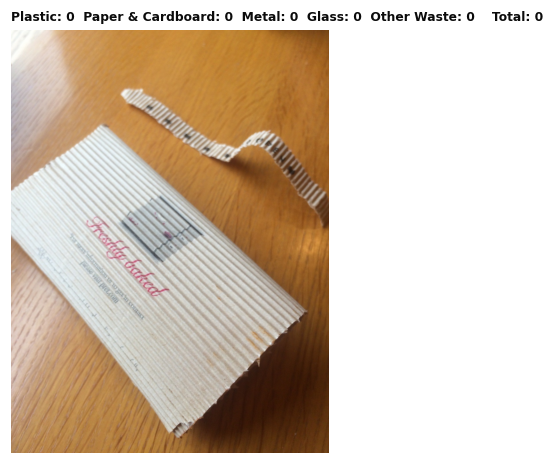

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://26dc13270bba7ad963.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:
def predict_image(img, conf=CONF_THRES, variant=SAM_NAME[SAM_VARIANTS[-1]]):
    if img is None:
        return None, "Upload an image"
    img = np.asarray(img)[..., :3].astype(np.uint8)
    s = min(1.0, MAX_SIDE / max(img.shape[:2]))
    if s < 1:
        img = cv2.resize(img, (round(img.shape[1] * s), round(img.shape[0] * s)), interpolation=cv2.INTER_AREA)
    v = {n: k for k, n in SAM_NAME.items()}[variant]
    r = det.predict(np.ascontiguousarray(img[..., ::-1]), conf=conf, imgsz=IMG_SIZE, device=YOLO_DEVICE,
                    agnostic_nms=True, verbose=False)[0]
    boxes, cls, sc = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy()
    H, W = img.shape[:2]
    masks = esam_decode(ESAM[v], esam_embed(ESAM[v], img), boxes, H, W) if len(boxes) else np.zeros((0, H, W), bool)
    c = Counter(CLASSES[k] for k in cls)
    return draw_instances(img, boxes, cls, sc, masks), "\n".join(f"{k}: {c[k]}" for k in CLASSES) + f"\n\nTotal: {len(cls)}"

# quick check on one test image
_vis, _txt = predict_image(load_rgb(test_ids[0]))
plt.figure(figsize=(7, 5)); plt.imshow(_vis); plt.axis("off"); plt.title(_txt.replace("\n", "  "), fontsize=8, loc="left"); plt.show()

if LAUNCH_DEMO:
    try:
        import gradio as gr
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
        import gradio as gr
    demo = gr.Interface(
        fn=predict_image,
        inputs=[gr.Image(type="numpy", label="Litter photo"),
                gr.Slider(0.05, 0.9, value=CONF_THRES, step=0.05, label="Detection confidence"),
                gr.Radio([SAM_NAME[v] for v in SAM_VARIANTS], value=SAM_NAME[SAM_VARIANTS[-1]], label="Segmenter")],
        outputs=[gr.Image(label="Boxes + EfficientSAM masks"), gr.Textbox(label="Litter count")],
        examples=[[str(FAST_IMG / images_all[i]["file_name"]), CONF_THRES, SAM_NAME[SAM_VARIANTS[-1]]] for i in test_ids[:4]],
        title="Automatic Litter Detection & Segmentation · YOLO + EfficientSAM",
        description="Team อุดมไปด้วยธาตุเหล็ก · CP461. Detects 5 litter classes, segments each object with EfficientSAM and counts them.")
    demo.launch(share=True, debug=False)